# Detección de Fraude en Tarjetas de Crédito — Grupo 33

**Diplomado en Ciencia de Datos y Análisis Avanzado — Proyecto Final Integrador**

**Integrantes:** Mariana Chaile · Eugenia Salcedo Aisa · Sol Kidonakis · Marco Garcia · Esteban Derghazarian

Notebook autocontenido (CRISP-DM). Métricas principales: **PR-AUC, Recall y Precision**. Métrica de negocio: captura **Top-100 / Top-500**. Validación: split **aleatorio** vs **temporal** por `Time`.

## 0. Setup y funciones del pipeline

In [ ]:


from pathlib import Path
from urllib.request import urlretrieve
import gc
import os
import warnings


for _k in (
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "VECLIB_MAXIMUM_THREADS",
    "NUMEXPR_NUM_THREADS",
):
    os.environ[_k] = "1"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from lightgbm import LGBMClassifier
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    ConfusionMatrixDisplay,
    f1_score,
    precision_recall_curve,
    PrecisionRecallDisplay,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

ROOT = next(
    (p for p in [Path.cwd(), Path.cwd().parent, Path("/content/TP_Final_DataScience")] if (p / "README.md").exists()),
    Path.cwd().parent,
)
DATA_CSV = ROOT / "data" / "creditcard.csv"
RESULTS = ROOT / "results"
(RESULTS / "figures").mkdir(parents=True, exist_ok=True)
(RESULTS / "tables").mkdir(parents=True, exist_ok=True)
TF_URL = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
PCA_COLS = [f"V{i}" for i in range(1, 29)]
print("ROOT:", ROOT)

ROOT: /home/rtadmin/TP_Final/TP_Final_DataScience


In [2]:
def load_creditcard(cache_path=None, force_download=False):
    cache_path = Path(cache_path) if cache_path else DATA_CSV
    cache_path.parent.mkdir(parents=True, exist_ok=True)
    if cache_path.exists() and not force_download:
        df = pd.read_csv(cache_path)
    else:
        try:
            urlretrieve(TF_URL, cache_path)
            df = pd.read_csv(cache_path)
        except Exception as exc:
            print("Mirror no disponible, OpenML:", exc)
            from sklearn.datasets import fetch_openml
            df = fetch_openml(data_id=1597, as_frame=True, parser="auto").frame.copy()
            df.to_csv(cache_path, index=False)
    cols = {c.lower(): c for c in df.columns}
    for e in ("time", "amount", "class"):
        if e in cols and cols[e] != e.capitalize():
            df = df.rename(columns={cols[e]: e.capitalize()})
    df["Class"] = pd.to_numeric(df["Class"], errors="coerce").astype(int)
    return df[["Time", *PCA_COLS, "Amount", "Class"]]


def clean_dataframe(df):
    before, before_fraud = len(df), int(df["Class"].sum())
    out = df.drop_duplicates().reset_index(drop=True)
    out.attrs["n_duplicates_removed"] = before - len(out)
    out.attrs["n_fraud_duplicates_removed"] = before_fraud - int(out["Class"].sum())
    return out


def add_features(df):
    out = df.copy()
    out["Amount_log"] = np.log1p(out["Amount"].astype(float))
    hour = (out["Time"] % 86400) / 3600.0
    out["Hour"] = hour
    out["Hour_sin"] = np.sin(2 * np.pi * hour / 24)
    out["Hour_cos"] = np.cos(2 * np.pi * hour / 24)
    return out


FEATURES = [*PCA_COLS, "Amount_log", "Hour_sin", "Hour_cos"]


def feature_target_split(df):
    return df[FEATURES], df["Class"].astype(int)


def random_split(X, y, test_size=0.2, random_state=42):
    return train_test_split(X, y, test_size=test_size, random_state=random_state, stratify=y)


def temporal_split(df, test_size=0.2):
    order = np.argsort(df["Time"].to_numpy(), kind="stable")
    cut = int(len(order) * (1 - test_size))
    train_i, test_i = order[:cut], order[cut:]
    X, y = feature_target_split(df)
    return X.iloc[train_i], X.iloc[test_i], y.iloc[train_i], y.iloc[test_i]

In [ ]:
def top_k(y_true, score, k):
    y = np.asarray(y_true).astype(int)
    s = np.asarray(score, dtype=float)
    k = min(int(k), len(y))
    idx = np.argsort(-s, kind="stable")[:k]
    found = int(y[idx].sum())
    n_pos = int(y.sum())
    prev = n_pos / len(y)
    prec = found / k
    return {
        "k": k,
        "fraudes": found,
        "precision_k": prec,
        "recall_k": found / n_pos if n_pos else 0.0,
        "lift_k": prec / prev if prev else 0.0,
    }


def at_threshold(y_true, score, threshold):
    y = np.asarray(y_true).astype(int)
    pred = np.asarray(score) >= threshold
    tp = int((pred & (y == 1)).sum())
    fp = int((pred & (y == 0)).sum())
    fn = int((~pred & (y == 1)).sum())
    alerts = tp + fp
    return {
        "umbral": float(threshold),
        "alertas": alerts,
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "precision": tp / alerts if alerts else 0.0,
        "recall": tp / (tp + fn) if (tp + fn) else 0.0,
        "f1": f1_score(y, pred.astype(int), zero_division=0),
        "fpr": fp / int((y == 0).sum()),
    }


def summary(y_true, score, ks=(100, 500)):
    row = {
        "pr_auc": average_precision_score(y_true, score),
        "roc_auc": roc_auc_score(y_true, score),
        "prevalencia": float(np.mean(y_true)),
    }
    for k in ks:
        t = top_k(y_true, score, k)
        row[f"fraudes@{k}"] = t["fraudes"]
        row[f"precision@{k}"] = t["precision_k"]
        row[f"recall@{k}"] = t["recall_k"]
        row[f"lift@{k}"] = t["lift_k"]
    return row


def scale_pos_weight(y):
    y = np.asarray(y).astype(int)
    return float((y == 0).sum() / max((y == 1).sum(), 1))


N_JOBS = min(4, os.cpu_count() or 1)


def make_estimator(name, y_train, random_state=42):
    spw = scale_pos_weight(y_train)
    if name == "Logística":
        return LogisticRegression(class_weight="balanced", max_iter=2000, random_state=random_state)
    if name == "Random Forest":
        return RandomForestClassifier(
            n_estimators=200, max_depth=12, min_samples_leaf=5,
            class_weight="balanced_subsample", n_jobs=N_JOBS, random_state=random_state,
        )
    if name in ("XGBoost", "XGBoost + SMOTE"):
        return XGBClassifier(
            n_estimators=300, max_depth=5, learning_rate=0.05, subsample=0.8,
            colsample_bytree=0.8, scale_pos_weight=1.0 if name == "XGBoost + SMOTE" else spw,
            eval_metric="aucpr", tree_method="hist", n_jobs=N_JOBS, random_state=random_state,
        )
    if name == "LightGBM":
        return LGBMClassifier(
            n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=50,
            subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
            scale_pos_weight=float(np.sqrt(spw)), n_jobs=N_JOBS, random_state=random_state, verbose=-1,
        )
    raise ValueError(name)


def build_pipeline(name, feature_names, y_train, random_state=42):
    scale_cols = [c for c in ("Amount_log", "Time") if c in feature_names]
    pre = ColumnTransformer([("scale", StandardScaler(), scale_cols)], remainder="passthrough", verbose_feature_names_out=False)
    clf = make_estimator(name, y_train, random_state)
    if name == "XGBoost + SMOTE":

        smote = SMOTE(sampling_strategy=0.1, random_state=random_state)
        return ImbPipeline([("pre", pre), ("smote", smote), ("clf", clf)])
    return Pipeline([("pre", pre), ("clf", clf)])


def predict_score(pipe, X):
    return pipe.predict_proba(X)[:, 1]


MODELS = ["Logística", "Random Forest", "XGBoost", "LightGBM", "XGBoost + SMOTE"]
print("N_JOBS:", N_JOBS)

N_JOBS: 4


## 1. Datos, limpieza y EDA

In [4]:
df_raw = load_creditcard()
print(df_raw.shape, "fraudes originales:", int(df_raw["Class"].sum()), f"({df_raw['Class'].mean():.4%})")
print("Nulos:", int(df_raw.isna().sum().sum()))
df = add_features(clean_dataframe(df_raw))
print("Duplicados eliminados:", df.attrs.get("n_duplicates_removed"), "(fraudes:", df.attrs.get("n_fraud_duplicates_removed"), ")")
print(df.shape, "fraudes:", int(df["Class"].sum()))
df.head()

(284807, 31) fraudes originales: 492 (0.1727%)
Nulos: 0
Duplicados eliminados: 1081 (fraudes: 19 )
(283726, 35) fraudes: 473


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V25,V26,V27,V28,Amount,Class,Amount_log,Hour,Hour_sin,Hour_cos
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,0.128539,-0.189115,0.133558,-0.021053,149.62,0,5.014760,0.000000,0.000000,1.0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,0.167170,0.125895,-0.008983,0.014724,2.69,0,1.305626,0.000000,0.000000,1.0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0,5.939276,0.000278,0.000073,1.0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,0.647376,-0.221929,0.062723,0.061458,123.50,0,4.824306,0.000278,0.000073,1.0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.206010,0.502292,0.219422,0.215153,69.99,0,4.262539,0.000556,0.000145,1.0


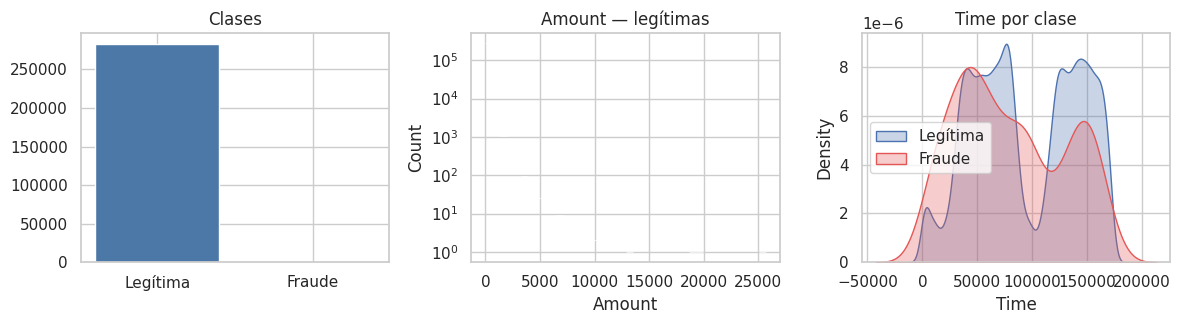

V17    0.313498
V14    0.293375
V12    0.250711
V10    0.206971
V16    0.187186
V3     0.182322
V7     0.172347
V11    0.149067
V4     0.129326
V18    0.105340
Name: Class, dtype: float64

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
counts = df["Class"].value_counts().sort_index()
axes[0].bar(["Legítima", "Fraude"], counts.values, color=["#4C78A8", "#E45756"])
axes[0].set_title("Clases")
sns.histplot(df.loc[df.Class == 0, "Amount"], bins=40, ax=axes[1], log_scale=(False, True), color="#4C78A8")
axes[1].set_title("Amount — legítimas")
sns.kdeplot(df.loc[df.Class == 0, "Time"], ax=axes[2], label="Legítima", fill=True, alpha=0.3)
sns.kdeplot(df.loc[df.Class == 1, "Time"], ax=axes[2], label="Fraude", fill=True, alpha=0.3, color="#E45756")
axes[2].set_title("Time por clase")
axes[2].legend()
plt.tight_layout()
plt.savefig(RESULTS / "figures" / "fig1_eda.png", dpi=140, bbox_inches="tight")
plt.show()

corr = df.corr(numeric_only=True)["Class"].drop("Class").abs().sort_values(ascending=False).head(10)
corr

## 2. Splits: aleatorio estratificado vs temporal

In [6]:
X, y = feature_target_split(df)
X_tr, X_te, y_tr, y_te = random_split(X, y)
X_tr_t, X_te_t, y_tr_t, y_te_t = temporal_split(df)
print("Aleatorio — train/test fraud:", int(y_tr.sum()), int(y_te.sum()), "n_test", len(y_te))
print("Temporal  — train/test fraud:", int(y_tr_t.sum()), int(y_te_t.sum()), "n_test", len(y_te_t))

Aleatorio — train/test fraud: 378 95 n_test 56746
Temporal  — train/test fraud: 399 74 n_test 56746


## 3. Modelado y evaluación

In [7]:
def evaluar(nombre_split, X_train, X_test, y_train, y_test):
    """Entrena cada modelo y guarda solo los scores (no los pipelines) para no acumular RAM."""
    rows, scores = [], {}
    for name in MODELS:
        print(f"→ {nombre_split}: entrenando {name}...", flush=True)
        pipe = build_pipeline(name, list(X_train.columns), y_train)
        pipe.fit(X_train, y_train)
        score = predict_score(pipe, X_test)
        scores[name] = score
        row = {"split": nombre_split, "modelo": name, **summary(y_test, score)}
        m05 = at_threshold(y_test, score, 0.5)
        row.update({f"{k}_0.5": m05[k] for k in ("precision", "recall", "f1", "alertas", "tp", "fp")})
        rows.append(row)
        print(
            f"{nombre_split:10s} | {name:18s} | PR-AUC={row['pr_auc']:.3f} | "
            f"R={m05['recall']:.3f} | P={m05['precision']:.3f} | @100={row['fraudes@100']}",
            flush=True,
        )
        del pipe
        gc.collect()
    return pd.DataFrame(rows), scores

tab_est, art_est = evaluar("aleatorio", X_tr, X_te, y_tr, y_te)
tab_tmp, art_tmp = evaluar("temporal", X_tr_t, X_te_t, y_tr_t, y_te_t)
comparativa = pd.concat([tab_est, tab_tmp], ignore_index=True)
comparativa.to_csv(RESULTS / "tables" / "test_estable.csv", index=False)
comparativa

→ aleatorio: entrenando Logística...
aleatorio  | Logística          | PR-AUC=0.681 | R=0.874 | P=0.056 | @100=74
→ aleatorio: entrenando Random Forest...
aleatorio  | Random Forest      | PR-AUC=0.803 | R=0.747 | P=0.934 | @100=77
→ aleatorio: entrenando XGBoost...
aleatorio  | XGBoost            | PR-AUC=0.813 | R=0.779 | P=0.851 | @100=77
→ aleatorio: entrenando LightGBM...
aleatorio  | LightGBM           | PR-AUC=0.801 | R=0.779 | P=0.902 | @100=75
→ aleatorio: entrenando XGBoost + SMOTE...
aleatorio  | XGBoost + SMOTE    | PR-AUC=0.811 | R=0.779 | P=0.787 | @100=75
→ temporal: entrenando Logística...
temporal   | Logística          | PR-AUC=0.757 | R=0.919 | P=0.024 | @100=59
→ temporal: entrenando Random Forest...
temporal   | Random Forest      | PR-AUC=0.815 | R=0.743 | P=0.902 | @100=60
→ temporal: entrenando XGBoost...
temporal   | XGBoost            | PR-AUC=0.798 | R=0.757 | P=0.800 | @100=58
→ temporal: entrenando LightGBM...
temporal   | LightGBM           | PR-AUC=0.762 

,split,modelo,pr_auc,roc_auc,prevalencia,fraudes@100,precision@100,recall@100,lift@100,fraudes@500,precision@500,recall@500,lift@500,precision_0.5,recall_0.5,f1_0.5,alertas_0.5,tp_0.5,fp_0.5
0,aleatorio,Logística,0.680637,0.963715,0.001674,74,0.74,0.778947,442.021474,80,0.160,0.842105,95.572211,0.055817,0.873684,0.104930,1487,83,1404
1,aleatorio,Random Forest,0.803357,0.970965,0.001674,77,0.77,0.810526,459.941263,80,0.160,0.842105,95.572211,0.934211,0.747368,0.830409,76,71,5
2,aleatorio,XGBoost,0.813074,0.975122,0.001674,77,0.77,0.810526,459.941263,81,0.162,0.852632,96.766863,0.850575,0.778947,0.813187,87,74,13
3,aleatorio,LightGBM,0.801237,0.968109,0.001674,75,0.75,0.789474,447.994737,79,0.158,0.831579,94.377558,0.902439,0.778947,0.836158,82,74,8
4,aleatorio,XGBoost + SMOTE,0.810991,0.979765,0.001674,75,0.75,0.789474,447.994737,80,0.160,0.842105,95.572211,0.787234,0.778947,0.783069,94,74,20
5,temporal,Logística,0.757384,0.985369,0.001304,59,0.59,0.797297,452.434324,64,0.128,0.864865,98.155243,0.023660,0.918919,0.046133,2874,68,2806
6,temporal,Random Forest,0.814692,0.989080,0.001304,60,0.60,0.810811,460.102703,65,0.130,0.878378,99.688919,0.901639,0.743243,0.814815,61,55,6
7,temporal,XGBoost,0.797865,0.982429,0.001304,58,0.58,0.783784,444.765946,63,0.126,0.851351,96.621568,0.800000,0.756757,0.777778,70,56,14
8,temporal,LightGBM,0.761862,0.981459,0.001304,58,0.58,0.783784,444.765946,63,0.126,0.851351,96.621568,0.753425,0.743243,0.748299,73,55,18
9,temporal,XGBoost + SMOTE,0.784989,0.985022,0.001304,57,0.57,0.770270,437.097568,61,0.122,0.824324,93.554216,0.740260,0.770270,0.754967,77,57,20


## 4. Modelo elegido, Top-K y carga de alertas

Mejor PR-AUC (aleatorio): XGBoost


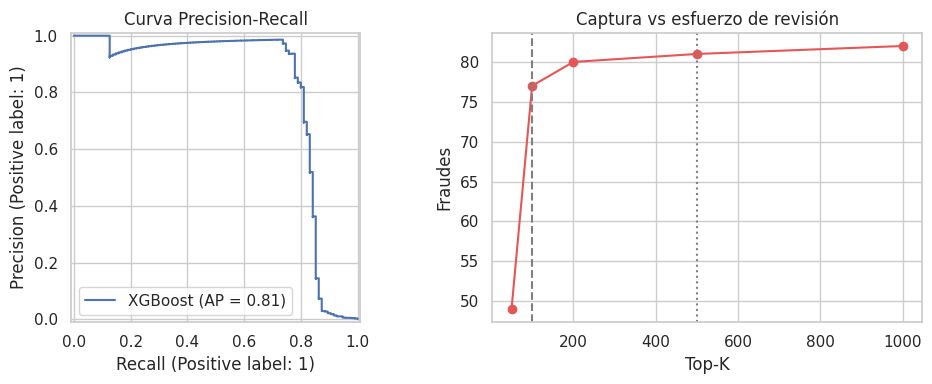

,k,fraudes,precision_k,recall_k,lift_k
0,50,49,0.980,0.515789,585.379789
1,100,77,0.770,0.810526,459.941263
2,200,80,0.400,0.842105,238.930526
3,500,81,0.162,0.852632,96.766863
4,1000,82,0.082,0.863158,48.980758


In [ ]:
best = tab_est.sort_values("pr_auc", ascending=False).iloc[0]["modelo"]
print("Mejor PR-AUC (aleatorio):", best)
score = art_est[best]
pipe = build_pipeline(best, list(X_tr.columns), y_tr)
pipe.fit(X_tr, y_tr)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
PrecisionRecallDisplay.from_predictions(y_te, score, ax=axes[0], name=best)
axes[0].set_title("Curva Precision-Recall")
topk = pd.DataFrame([top_k(y_te, score, k) for k in (50, 100, 200, 500, 1000)])
axes[1].plot(topk["k"], topk["fraudes"], marker="o", color="#E45756")
axes[1].axvline(100, ls="--", color="gray")
axes[1].axvline(500, ls=":", color="gray")
axes[1].set_xlabel("Top-K"); axes[1].set_ylabel("Fraudes")
axes[1].set_title("Captura vs esfuerzo de revisión")
plt.tight_layout()
plt.savefig(RESULTS / "figures" / "fig2_test_estable.png", dpi=140, bbox_inches="tight")
plt.show()
display(topk)
topk.to_csv(RESULTS / "tables" / "topk_estable.csv", index=False)

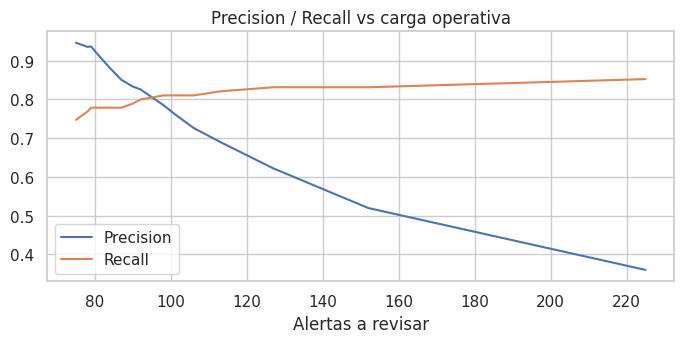

,umbral,alertas,tp,fp,fn,precision,recall,f1,fpr
0,0.05,225,81,144,14,0.360000,0.852632,0.506250,0.002542
1,0.10,152,79,73,16,0.519737,0.831579,0.639676,0.001289
2,0.15,127,79,48,16,0.622047,0.831579,0.711712,0.000847
3,0.20,113,78,35,17,0.690265,0.821053,0.750000,0.000618
4,0.25,106,77,29,18,0.726415,0.810526,0.766169,0.000512
5,0.30,101,77,24,18,0.762376,0.810526,0.785714,0.000424
6,0.35,98,77,21,18,0.785714,0.810526,0.797927,0.000371
7,0.40,92,76,16,19,0.826087,0.800000,0.812834,0.000282


Referencia FPR 5 % sobre legítimas del holdout ≈ 2832 alertas falsas


In [9]:
ths = np.round(np.linspace(0.05, 0.95, 19), 2)
wl = pd.DataFrame([at_threshold(y_te, score, t) for t in ths])
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(wl["alertas"], wl["precision"], label="Precision")
ax.plot(wl["alertas"], wl["recall"], label="Recall")
ax.set_xlabel("Alertas a revisar"); ax.set_title("Precision / Recall vs carga operativa")
ax.legend()
plt.tight_layout()
plt.savefig(RESULTS / "figures" / "fig5_umbral_alertas.png", dpi=140, bbox_inches="tight")
plt.show()
display(wl.head(8))
print("Referencia FPR 5 % sobre legítimas del holdout ≈", int(0.05 * (y_te == 0).sum()), "alertas falsas")

## 5. Validación temporal

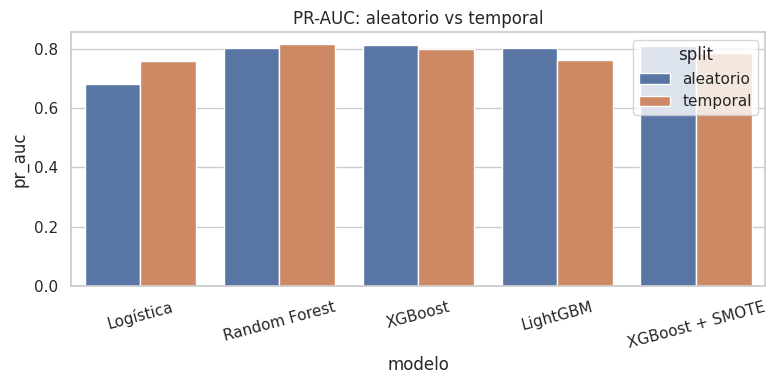

,modelo,pr_auc,recall_0.5,precision_0.5,fraudes@100,fraudes@500
0,Logística,0.757384,0.918919,0.023660,59,64
1,Random Forest,0.814692,0.743243,0.901639,60,65
2,XGBoost,0.797865,0.756757,0.800000,58,63
3,LightGBM,0.761862,0.743243,0.753425,58,63
4,XGBoost + SMOTE,0.784989,0.770270,0.740260,57,61


In [10]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=comparativa, x="modelo", y="pr_auc", hue="split", ax=ax)
ax.set_title("PR-AUC: aleatorio vs temporal")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig(RESULTS / "figures" / "fig3_temporal.png", dpi=140, bbox_inches="tight")
plt.show()
display(tab_tmp[["modelo", "pr_auc", "recall_0.5", "precision_0.5", "fraudes@100", "fraudes@500"]])

## 6. Interpretación

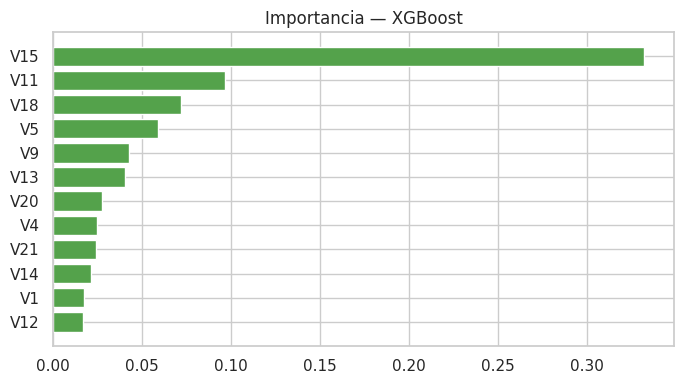

In [11]:
clf = pipe.named_steps["clf"]
imp = getattr(clf, "feature_importances_", None)
if imp is None and hasattr(clf, "coef_"):
    imp = np.abs(clf.coef_).ravel()
if imp is not None:
    names = list(X_tr.columns)
    n = min(len(imp), len(names))
    orden = np.argsort(imp[:n])[-12:]
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.barh(np.array(names)[orden], imp[orden], color="#54A24B")
    ax.set_title(f"Importancia — {best}")
    plt.tight_layout()
    plt.savefig(RESULTS / "figures" / "fig4_interpretacion.png", dpi=140, bbox_inches="tight")
    plt.show()

## 7. Conclusiones

1. El producto es un **ranking** para la cola de revisión, no un sí/no rígido.
2. Métricas que importan: **PR-AUC, Recall, Precision** y **cuántas alertas** sale a revisar el equipo.
3. **Top-100 / Top-500** traducen el score a esfuerzo de negocio.
4. El split **temporal** es más realista que el aleatorio; usarlo antes de un piloto.
5. Informe escrito: `docs/Informe_Final_Grupo33.pdf`.